In [ ]:
import pandas as pd
df = pd.read_csv("INvideos.csv")
print(df.tail())

          video_id trending_date  \
37347  iNHecA3PJCo      18.14.06   
37348  dpPmPbhcslM      18.14.06   
37349  mV6aztP58f8      18.14.06   
37350  qxqDNP1bDEw      18.14.06   
37351  wERgpPK44w0      18.14.06   

                                                   title       channel_title  \
37347  फेकू आशिक़ - राजस्थान की सबसे शानदार कॉमेडी | ...      RDC Rajasthani   
37348                         Seetha | Flowers | Ep# 364          Flowers TV   
37349  Bhramanam I Episode 87 - 12 June 2018 I Mazhav...   Mazhavil Manorama   
37350  Nua Bohu | Full Ep 285 | 13th June 2018 | Odia...           Tarang TV   
37351  Ee Nagaraniki Emaindi Trailer | Tharun Bhascke...  Suresh Productions   

       category_id              publish_time  \
37347           23  2018-06-13T08:01:11.000Z   
37348           24  2018-06-13T11:30:04.000Z   
37349           24  2018-06-13T05:00:02.000Z   
37350           24  2018-06-13T15:07:49.000Z   
37351           24  2018-06-10T04:29:54.000Z   

             

In [ ]:
df.columns

Index(['video_id', 'trending_date', 'title', 'channel_title', 'category_id',
       'publish_time', 'tags', 'views', 'likes', 'dislikes', 'comment_count',
       'thumbnail_link', 'comments_disabled', 'ratings_disabled',
       'video_error_or_removed', 'description'],
      dtype='object')

In [ ]:
df.shape

(37352, 16)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37352 entries, 0 to 37351
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   video_id                37352 non-null  object
 1   trending_date           37352 non-null  object
 2   title                   37352 non-null  object
 3   channel_title           37352 non-null  object
 4   category_id             37352 non-null  int64 
 5   publish_time            37352 non-null  object
 6   tags                    37352 non-null  object
 7   views                   37352 non-null  int64 
 8   likes                   37352 non-null  int64 
 9   dislikes                37352 non-null  int64 
 10  comment_count           37352 non-null  int64 
 11  thumbnail_link          37352 non-null  object
 12  comments_disabled       37352 non-null  bool  
 13  ratings_disabled        37352 non-null  bool  
 14  video_error_or_removed  37352 non-null  bool  
 15  de

In [ ]:
df.isnull().sum()

,0
video_id,0
trending_date,0
title,0
channel_title,0
category_id,0
publish_time,0
tags,0
views,0
likes,0
dislikes,0


In [ ]:
!pip install pyspark

In [ ]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("YouTube Video Statistics Analysis") \
    .getOrCreate()

print("Spark Version:", spark.version)

Spark Version: 4.0.4


In [ ]:
df = spark.read.csv(
    "INvideos.csv",
    header=True,
    inferSchema=True
)

df.show(5)

+-----------+-------------+--------------------+---------------+-----------+--------------------+--------------------+-------+-----+--------+-------------+--------------------+-----------------+----------------+----------------------+--------------------+
|   video_id|trending_date|               title|  channel_title|category_id|        publish_time|                tags|  views|likes|dislikes|comment_count|      thumbnail_link|comments_disabled|ratings_disabled|video_error_or_removed|         description|
+-----------+-------------+--------------------+---------------+-----------+--------------------+--------------------+-------+-----+--------+-------------+--------------------+-----------------+----------------+----------------------+--------------------+
|kzwfHumJyYc|     17.14.11|Sharry Mann: Cute...|Lokdhun Punjabi|          1|2017-11-12T12:20:...|"sharry mann|""sh...|1096327|33966|     798|          882|https://i.ytimg.c...|            false|           false|                 fals

In [ ]:
print("Total Rows:", df.count())
print("Total Columns:", len(df.columns))

df.printSchema()

Total Rows: 38528
Total Columns: 16
root
 |-- video_id: string (nullable = true)
 |-- trending_date: string (nullable = true)
 |-- title: string (nullable = true)
 |-- channel_title: string (nullable = true)
 |-- category_id: string (nullable = true)
 |-- publish_time: string (nullable = true)
 |-- tags: string (nullable = true)
 |-- views: string (nullable = true)
 |-- likes: string (nullable = true)
 |-- dislikes: string (nullable = true)
 |-- comment_count: integer (nullable = true)
 |-- thumbnail_link: string (nullable = true)
 |-- comments_disabled: boolean (nullable = true)
 |-- ratings_disabled: boolean (nullable = true)
 |-- video_error_or_removed: boolean (nullable = true)
 |-- description: string (nullable = true)



In [ ]:
df.show(10, truncate=False)

+-----------+-------------+-------------------------------------------------------------------------------------------------+----------------+-----------+------------------------+----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+--------+------+--------+-------------+----------------------------------------------+-----------------+----------------+----------------------+------------------------------------------------------------------------------------------------------------------------------------

In [ ]:
# Check missing values
from pyspark.sql.functions import col, sum

df.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in df.columns
]).show()

+--------+-------------+-----+-------------+-----------+------------+----+-----+-----+--------+-------------+--------------+-----------------+----------------+----------------------+-----------+
|video_id|trending_date|title|channel_title|category_id|publish_time|tags|views|likes|dislikes|comment_count|thumbnail_link|comments_disabled|ratings_disabled|video_error_or_removed|description|
+--------+-------------+-----+-------------+-----------+------------+----+-----+-----+--------+-------------+--------------+-----------------+----------------+----------------------+-----------+
|       0|          911|  993|         1106|       1139|        1152|1164| 1172| 1174|    1176|         1177|          1177|             1177|            1177|                  1177|       1738|
+--------+-------------+-----+-------------+-----------+------------+----+-----+-----+--------+-------------+--------------+-----------------+----------------+----------------------+-----------+



In [ ]:
print("Before duplicates:", df.count())

df = df.dropDuplicates()

print("After duplicates:", df.count())

Before duplicates: 38528
After duplicates: 33320


In [ ]:
# Remove rows with missing values in important columns

youtube_df = df.dropna(
    subset=[
        "video_id",
        "title",
        "channel_title",
        "category_id",
        "views",
        "likes",
        "dislikes",
        "comment_count"
    ]
)

print("Rows after removing missing values:", youtube_df.count())

Rows after removing missing values: 33088


In [ ]:
youtube_df.select([
    sum(col(c).isNull().cast("int")).alias(c)
    for c in youtube_df.columns
]).show()

+--------+-------------+-----+-------------+-----------+------------+----+-----+-----+--------+-------------+--------------+-----------------+----------------+----------------------+-----------+
|video_id|trending_date|title|channel_title|category_id|publish_time|tags|views|likes|dislikes|comment_count|thumbnail_link|comments_disabled|ratings_disabled|video_error_or_removed|description|
+--------+-------------+-----+-------------+-----------+------------+----+-----+-----+--------+-------------+--------------+-----------------+----------------+----------------------+-----------+
|       0|            0|    0|            0|          0|           0|   0|    0|    0|       0|            0|             0|                0|               0|                     0|        527|
+--------+-------------+-----+-------------+-----------+------------+----+-----+-----+--------+-------------+--------------+-----------------+----------------+----------------------+-----------+



In [ ]:
youtube_df = df.select(
    "video_id",
    "title",
    "channel_title",
    "category_id",
    "publish_time",
    "views",
    "likes",
    "dislikes",
    "comment_count"
)

youtube_df.show(5, truncate=False)

+-----------+-----------------------------------------------------------------------------------------------+----------------+-----------+------------------------+------+-----+--------+-------------+
|video_id   |title                                                                                          |channel_title   |category_id|publish_time            |views |likes|dislikes|comment_count|
+-----------+-----------------------------------------------------------------------------------------------+----------------+-----------+------------------------+------+-----+--------+-------------+
|gW4Su5wq0b8|Neeya Naana - 12th November 2017 - Promo 2                                                     |Vijay Television|24         |2017-11-11T07:49:46.000Z|261202|1971 |126     |201          |
|hJ6nM40tuKQ|ലൈവിൽ വന്നു ഭാരിയക്ക്‌  പാട്ടു പാടി കൊടുത്തു ചാക്കോച്ചൻ.!!! ക്ലൈമാക്സ്‌ മിസ്സ്‌ ആക്കല്ലേ... !!!|Malayalam Media |24         |2017-11-13T01:53:12.000Z|209606|3739 |118     |245          |


In [ ]:
youtube_df.select(
    "views",
    "likes",
    "dislikes",
    "comment_count"
).describe().show()

+-------+-----------------+--------------------+--------------------+------------------+
|summary|            views|               likes|            dislikes|     comment_count|
+-------+-----------------+--------------------+--------------------+------------------+
|  count|            33093|               33091|               33089|             33088|
|   mean|996370.9483498549|   25588.35073138298|  1576.5797872340424|2524.8458051257253|
| stddev|3148153.907483704|    96474.5615664211|  16895.982401049157|14770.043101450508|
|    min|          Support| Subscribe▬▬▬▬▬▬▬...| Subscribe▬▬▬▬▬▬▬...|                 0|
|    max|          9998338|                9996|                 999|            827755|
+-------+-----------------+--------------------+--------------------+------------------+



In [ ]:
youtube_df.printSchema()

root
 |-- video_id: string (nullable = true)
 |-- title: string (nullable = true)
 |-- channel_title: string (nullable = true)
 |-- category_id: string (nullable = true)
 |-- publish_time: string (nullable = true)
 |-- views: string (nullable = true)
 |-- likes: string (nullable = true)
 |-- dislikes: string (nullable = true)
 |-- comment_count: integer (nullable = true)



In [ ]:
youtube_df.select(
    "views",
    "likes",
    "dislikes",
    "comment_count"
).show(20, truncate=False)

+-------+-----+--------+-------------+
|views  |likes|dislikes|comment_count|
+-------+-----+--------+-------------+
|261202 |1971 |126     |201          |
|209606 |3739 |118     |245          |
|353787 |24062|510     |1011         |
|50641  |1305 |32      |187          |
|70360  |386  |110     |125          |
|165157 |484  |99      |68           |
|83419  |658  |86      |132          |
|800439 |35972|1324    |2004         |
|297095 |1147 |497     |158          |
|509903 |2295 |1305    |2733         |
|217570 |433  |177     |75           |
|2051238|57128|3290    |1737         |
|12129  |93   |2       |8            |
|88983  |574  |162     |111          |
|123941 |152  |56      |293          |
|57311  |541  |34      |78           |
|163212 |773  |118     |109          |
|477554 |1377 |213     |92           |
|465711 |6814 |641     |422          |
|244216 |2767 |468     |255          |
+-------+-----+--------+-------------+
only showing top 20 rows


In [ ]:
from pyspark.sql.functions import col

youtube_df = youtube_df.withColumn(
    "views", col("views").cast("long")
).withColumn(
    "likes", col("likes").cast("long")
).withColumn(
    "dislikes", col("dislikes").cast("long")
).withColumn(
    "comment_count", col("comment_count").cast("long")
)

In [ ]:
from pyspark.sql.functions import col, expr

youtube_df = df.select(
    "video_id",
    "title",
    "channel_title",
    "category_id",
    "publish_time",
    "views",
    "likes",
    "dislikes",
    "comment_count"
)

youtube_df = youtube_df.withColumn(
    "views", expr("try_cast(views as BIGINT)")
).withColumn(
    "likes", expr("try_cast(likes as BIGINT)")
).withColumn(
    "dislikes", expr("try_cast(dislikes as BIGINT)")
).withColumn(
    "comment_count", expr("try_cast(comment_count as BIGINT)")
)

In [ ]:
youtube_df = youtube_df.dropna(
    subset=[
        "views",
        "likes",
        "dislikes",
        "comment_count"
    ]
)

print("Rows after cleaning:", youtube_df.count())

Rows after cleaning: 33088


In [ ]:
youtube_df.printSchema()

root
 |-- video_id: string (nullable = true)
 |-- title: string (nullable = true)
 |-- channel_title: string (nullable = true)
 |-- category_id: string (nullable = true)
 |-- publish_time: string (nullable = true)
 |-- views: long (nullable = true)
 |-- likes: long (nullable = true)
 |-- dislikes: long (nullable = true)
 |-- comment_count: long (nullable = true)



In [ ]:
youtube_df.select(
    "views",
    "likes",
    "dislikes",
    "comment_count"
).describe().show()

+-------+-----------------+-----------------+------------------+------------------+
|summary|            views|            likes|          dislikes|     comment_count|
+-------+-----------------+-----------------+------------------+------------------+
|  count|            33088|            33088|             33088|             33088|
|   mean|996370.9483498549|25588.35073138298|1576.5797872340424|2524.8458051257253|
| stddev|3148153.907483704| 96474.5615664211|16895.982401049157|14770.043101450508|
|    min|             4024|                0|                 0|                 0|
|    max|        125432237|          2912710|           1545017|            827755|
+-------+-----------------+-----------------+------------------+------------------+



In [ ]:
from pyspark.sql.functions import col

top_views = youtube_df.orderBy(
    col("views").desc()
)

top_views.select(
    "title",
    "channel_title",
    "views"
).show(10, truncate=False)

+-------------------------------------------------------+--------------------+---------+
|title                                                  |channel_title       |views    |
+-------------------------------------------------------+--------------------+---------+
|YouTube Rewind: The Shape of 2017 | #YouTubeRewind     |YouTube Spotlight   |125432237|
|YouTube Rewind: The Shape of 2017 | #YouTubeRewind     |YouTube Spotlight   |113876217|
|YouTube Rewind: The Shape of 2017 | #YouTubeRewind     |YouTube Spotlight   |100911567|
|Marvel Studios' Avengers: Infinity War Official Trailer|Marvel Entertainment|89930713 |
|Marvel Studios' Avengers: Infinity War Official Trailer|Marvel Entertainment|87449453 |
|Marvel Studios' Avengers: Infinity War Official Trailer|Marvel Entertainment|84281319 |
|Marvel Studios' Avengers: Infinity War Official Trailer|Marvel Entertainment|80360459 |
|YouTube Rewind: The Shape of 2017 | #YouTubeRewind     |YouTube Spotlight   |75969469 |
|Marvel Studios' Aven

In [ ]:
top_likes = youtube_df.orderBy(
    col("likes").desc()
)

top_likes.select(
    "title",
    "channel_title",
    "likes"
).show(10, truncate=False)

+-------------------------------------------------------+--------------------+-------+
|title                                                  |channel_title       |likes  |
+-------------------------------------------------------+--------------------+-------+
|YouTube Rewind: The Shape of 2017 | #YouTubeRewind     |YouTube Spotlight   |2912710|
|YouTube Rewind: The Shape of 2017 | #YouTubeRewind     |YouTube Spotlight   |2811216|
|YouTube Rewind: The Shape of 2017 | #YouTubeRewind     |YouTube Spotlight   |2656672|
|Marvel Studios' Avengers: Infinity War Official Trailer|Marvel Entertainment|2606663|
|Marvel Studios' Avengers: Infinity War Official Trailer|Marvel Entertainment|2584674|
|Marvel Studios' Avengers: Infinity War Official Trailer|Marvel Entertainment|2555411|
|Marvel Studios' Avengers: Infinity War Official Trailer|Marvel Entertainment|2513102|
|Marvel Studios' Avengers: Infinity War Official Trailer|Marvel Entertainment|2444956|
|Marvel Studios' Avengers: Infinity War Off

In [ ]:
top_comments = youtube_df.orderBy(
    col("comment_count").desc()
)

top_comments.select(
    "title",
    "channel_title",
    "comment_count"
).show(10, truncate=False)

+-------------------------------------------------------------------------------+-----------------+-------------+
|title                                                                          |channel_title    |comment_count|
+-------------------------------------------------------------------------------+-----------------+-------------+
|YouTube Rewind: The Shape of 2017 | #YouTubeRewind                             |YouTube Spotlight|827755       |
|YouTube Rewind: The Shape of 2017 | #YouTubeRewind                             |YouTube Spotlight|807558       |
|YouTube Rewind: The Shape of 2017 | #YouTubeRewind                             |YouTube Spotlight|787174       |
|YouTube Rewind: The Shape of 2017 | #YouTubeRewind                             |YouTube Spotlight|702784       |
|YouTube Rewind: The Shape of 2017 | #YouTubeRewind                             |YouTube Spotlight|682890       |
|YouTube Rewind: The Shape of 2017 | #YouTubeRewind                             |YouTube

In [ ]:
from pyspark.sql.functions import sum

channel_analysis = youtube_df.groupBy(
    "channel_title"
).agg(
    sum("views").alias("total_views"),
    sum("likes").alias("total_likes"),
    sum("comment_count").alias("total_comments")
).orderBy(
    col("total_views").desc()
)

channel_analysis.show(10, truncate=False)

+---------------------------+-----------+-----------+--------------+
|channel_title              |total_views|total_likes|total_comments|
+---------------------------+-----------+-----------+--------------+
|T-Series                   |1748057724 |31812724   |2163936       |
|Marvel Entertainment       |1058174340 |34188269   |4201145       |
|FoxStarHindi               |982953616  |19260709   |1422502       |
|Amit Bhadana               |855533181  |52376821   |5480376       |
|Speed Records              |648890913  |17611166   |1191255       |
|Goldmines Telefilms        |592596907  |4469166    |244226        |
|Sony Pictures Entertainment|587519233  |13905954   |1584005       |
|Zee Music Company          |556309816  |7437619    |428002        |
|YRF                        |549492884  |10187980   |907383        |
|Dude Perfect               |527111130  |20847765   |1515061       |
+---------------------------+-----------+-----------+--------------+
only showing top 10 rows


In [ ]:
category_analysis = youtube_df.groupBy(
    "category_id"
).agg(
    sum("views").alias("total_views"),
    sum("likes").alias("total_likes"),
    sum("comment_count").alias("total_comments")
).orderBy(
    col("total_views").desc()
)

category_analysis.show(10, truncate=False)


+-----------+-----------+-----------+--------------+
|category_id|total_views|total_likes|total_comments|
+-----------+-----------+-----------+--------------+
|24         |13326399551|328229550  |35486403      |
|10         |8336504205 |213063323  |14558095      |
|1          |3273144924 |57790703   |4844060       |
|23         |2423485988 |146425199  |11560689      |
|25         |1658522947 |13448058   |2534757       |
|17         |1192613734 |28473825   |2346624       |
|22         |1146217515 |19883239   |2331943       |
|26         |674464823  |7247108    |693467        |
|28         |435729557  |18121097   |7580486       |
|20         |198350285  |5100129    |485860        |
+-----------+-----------+-----------+--------------+
only showing top 10 rows


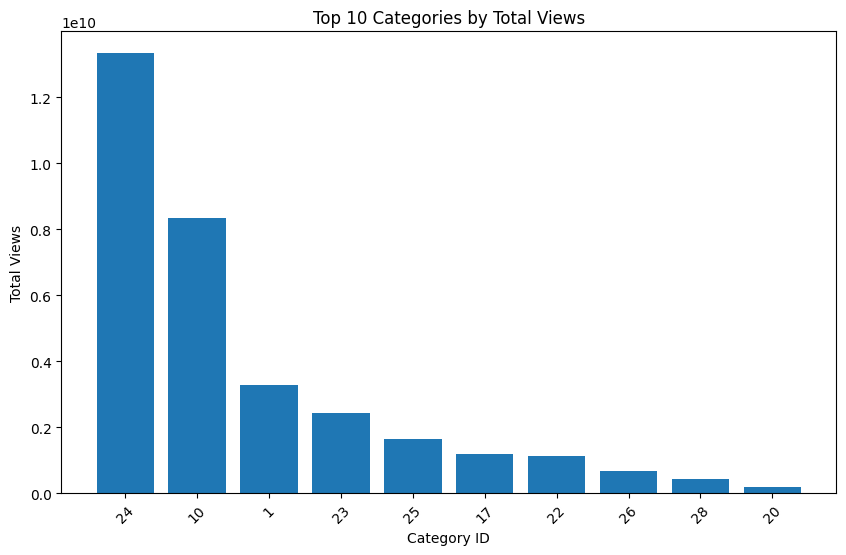

In [ ]:
import matplotlib.pyplot as plt

category_pd = category_analysis.limit(10).toPandas()

plt.figure(figsize=(10,6))
plt.bar(
    category_pd["category_id"],
    category_pd["total_views"]
)

plt.xlabel("Category ID")
plt.ylabel("Total Views")
plt.title("Top 10 Categories by Total Views")
plt.xticks(rotation=45)
plt.show()

In [ ]:
from pyspark.sql.functions import when

youtube_df = youtube_df.withColumn(
    "engagement_rate",
    when(
        col("views") > 0,
        ((col("likes") + col("comment_count")) / col("views")) * 100
    ).otherwise(0)
)

youtube_df.select(
    "title",
    "views",
    "likes",
    "comment_count",
    "engagement_rate"
).orderBy(
    col("engagement_rate").desc()
).show(10, truncate=False)

+-------------------------------------------------------------------------------+-------+------+-------------+------------------+
|title                                                                          |views  |likes |comment_count|engagement_rate   |
+-------------------------------------------------------------------------------+-------+------+-------------+------------------+
|OnePlus 6 Top Features and GIVEAWAY 🔥- OnePlus 6 Avengers Edition Giveaway!!🔥|840727 |321088|329872       |77.4282258093293  |
|Oneplus 5T Lava Red Unboxing and Giveaway 🔥🔥🔥 Valentine's Gift!!            |335058 |122284|108681       |68.93284147819183 |
|OnePlus 6 Top Features and GIVEAWAY 🔥- OnePlus 6 Avengers Edition Giveaway!!🔥|1049339|355742|367019       |68.87774113036875 |
|OnePlus 6 Top Features and GIVEAWAY 🔥- OnePlus 6 Avengers Edition Giveaway!!🔥|1158291|370533|382685       |65.02839096565543 |
|OnePlus 5T Star Wars Limited Edition Unboxing and First Look *GIVEAWAY*        |446587 |148132|131

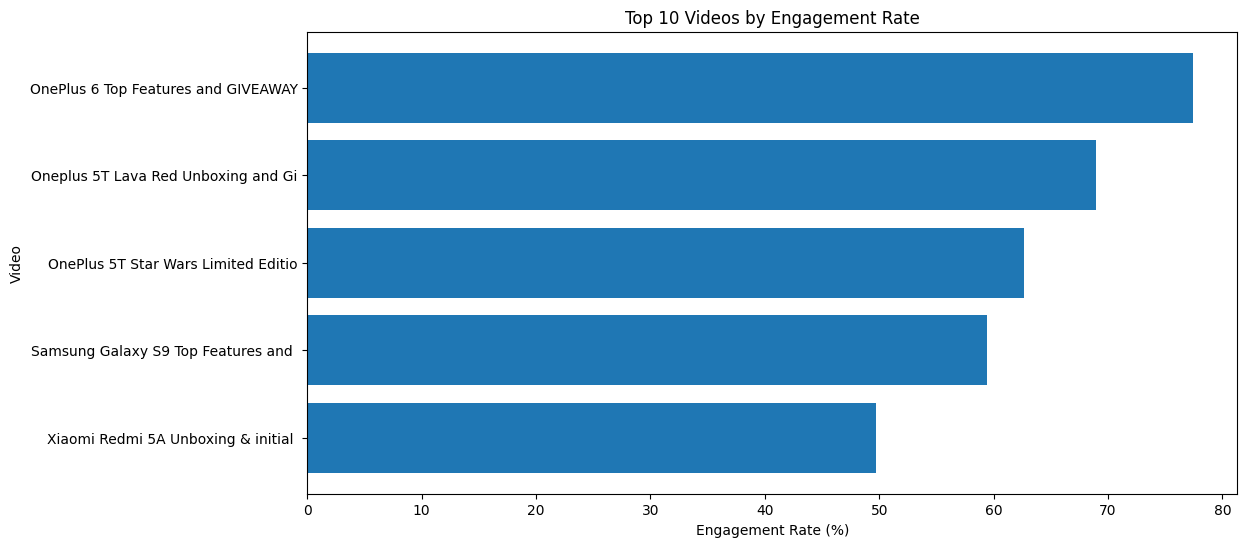

In [ ]:
engagement_pd = youtube_df.orderBy(
    col("engagement_rate").desc()
).limit(10).toPandas()

plt.figure(figsize=(12,6))

plt.barh(
    engagement_pd["title"].str[:35],
    engagement_pd["engagement_rate"]
)

plt.xlabel("Engagement Rate (%)")
plt.ylabel("Video")
plt.title("Top 10 Videos by Engagement Rate")
plt.gca().invert_yaxis()

plt.show()

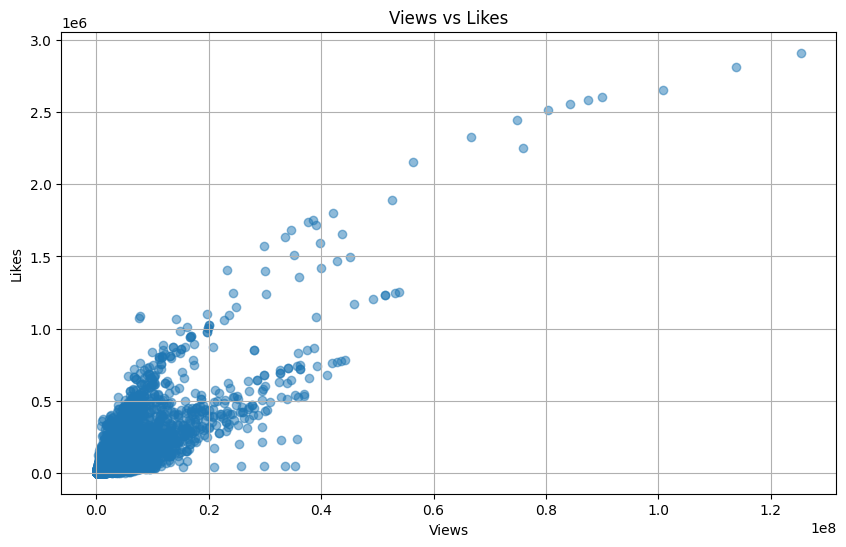

In [ ]:
import matplotlib.pyplot as plt

views_likes_pd = youtube_df.select(
    "views", "likes"
).toPandas()

plt.figure(figsize=(10, 6))

plt.scatter(
    views_likes_pd["views"],
    views_likes_pd["likes"],
    alpha=0.5
)

plt.xlabel("Views")
plt.ylabel("Likes")
plt.title("Views vs Likes")
plt.grid(True)

plt.show()

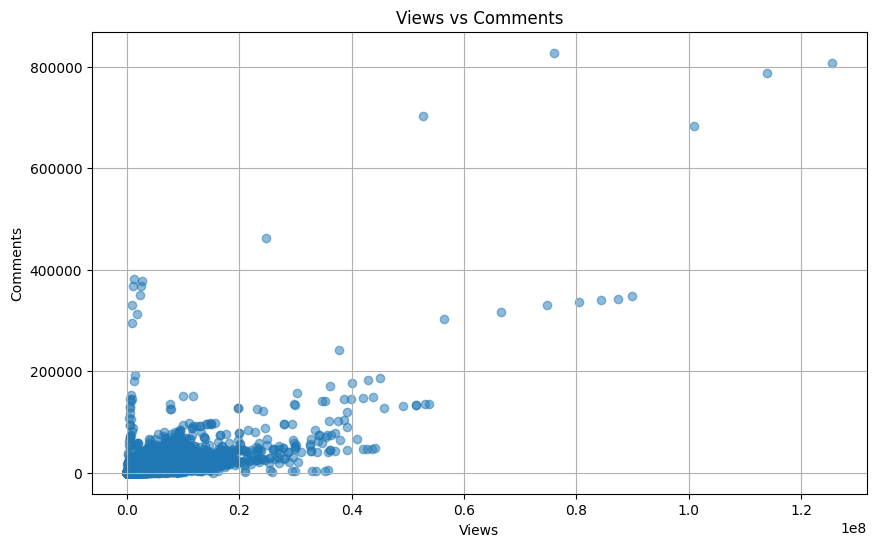

In [ ]:
import matplotlib.pyplot as plt

views_comments_pd = youtube_df.select(
    "views", "comment_count"
).toPandas()

plt.figure(figsize=(10, 6))

plt.scatter(
    views_comments_pd["views"],
    views_comments_pd["comment_count"],
    alpha=0.5
)

plt.xlabel("Views")
plt.ylabel("Comments")
plt.title("Views vs Comments")
plt.grid(True)

plt.show()

In [ ]:
!pip install plotly ipywidgets -q

In [ ]:
import plotly.express as px
import pandas as pd
import ipywidgets as widgets

from IPython.display import display, HTML

In [ ]:
# KPI values
total_videos = youtube_df.count()

total_views = youtube_df.selectExpr(
    "sum(views) as total"
).collect()[0]["total"]

total_likes = youtube_df.selectExpr(
    "sum(likes) as total"
).collect()[0]["total"]

total_comments = youtube_df.selectExpr(
    "sum(comment_count) as total"
).collect()[0]["total"]

print("Dashboard data ready!")

Dashboard data ready!


In [ ]:
channel_pd = channel_analysis.limit(10).toPandas()

channel_pd

,channel_title,total_views,total_likes,total_comments
0,T-Series,1748057724,31812724,2163936
1,Marvel Entertainment,1058174340,34188269,4201145
2,FoxStarHindi,982953616,19260709,1422502
3,Amit Bhadana,855533181,52376821,5480376
4,Speed Records,648890913,17611166,1191255
5,Goldmines Telefilms,592596907,4469166,244226
6,Sony Pictures Entertainment,587519233,13905954,1584005
7,Zee Music Company,556309816,7437619,428002
8,YRF,549492884,10187980,907383
9,Dude Perfect,527111130,20847765,1515061


In [ ]:
category_pd = category_analysis.limit(10).toPandas()

category_pd

,category_id,total_views,total_likes,total_comments
0,24,13326399551,328229550,35486403
1,10,8336504205,213063323,14558095
2,1,3273144924,57790703,4844060
3,23,2423485988,146425199,11560689
4,25,1658522947,13448058,2534757
5,17,1192613734,28473825,2346624
6,22,1146217515,19883239,2331943
7,26,674464823,7247108,693467
8,28,435729557,18121097,7580486
9,20,198350285,5100129,485860


In [ ]:
engagement_pd = youtube_df.orderBy(
    col("engagement_rate").desc()
).limit(10).select(
    "title",
    "channel_title",
    "views",
    "likes",
    "comment_count",
    "engagement_rate"
).toPandas()

engagement_pd

,title,channel_title,views,likes,comment_count,engagement_rate
0,OnePlus 6 Top Features and GIVEAWAY 🔥- OnePlus...,Technical Guruji,840727,321088,329872,77.428226
1,Oneplus 5T Lava Red Unboxing and Giveaway 🔥🔥🔥 ...,Technical Guruji,335058,122284,108681,68.932841
2,OnePlus 6 Top Features and GIVEAWAY 🔥- OnePlus...,Technical Guruji,1049339,355742,367019,68.877741
3,OnePlus 6 Top Features and GIVEAWAY 🔥- OnePlus...,Technical Guruji,1158291,370533,382685,65.028391
4,OnePlus 5T Star Wars Limited Edition Unboxing ...,Technical Guruji,446587,148132,131842,62.691928
5,Samsung Galaxy S9 Top Features and Tips Tricks...,Technical Guruji,921731,252602,295139,59.425255
6,Oneplus 5T Lava Red Unboxing and Giveaway 🔥🔥🔥 ...,Technical Guruji,446879,131887,118594,56.051191
7,OnePlus 5T Star Wars Limited Edition Unboxing ...,Technical Guruji,559686,165108,145754,55.542215
8,OnePlus 5T Star Wars Limited Edition Unboxing ...,Technical Guruji,611786,173149,153049,53.318971
9,Xiaomi Redmi 5A Unboxing & initial impressions...,Prasadtechintelugu,60209,12706,17221,49.705194


In [ ]:
views_likes_pd = youtube_df.select(
    "views",
    "likes"
).toPandas()

In [ ]:
views_comments_pd = youtube_df.select(
    "views",
    "comment_count"
).toPandas()

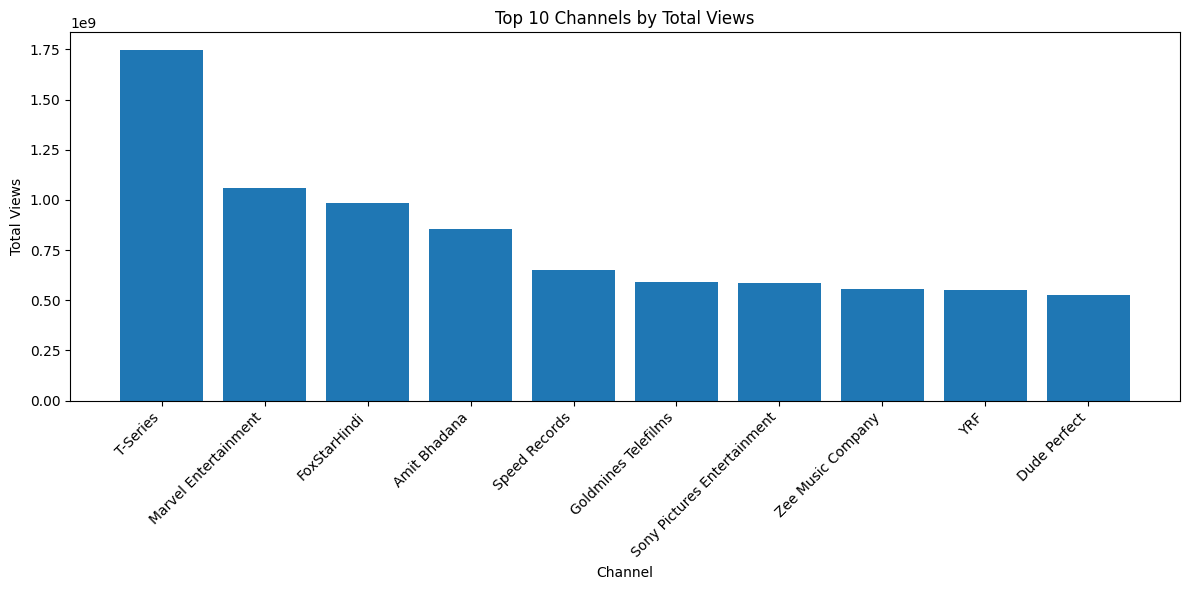

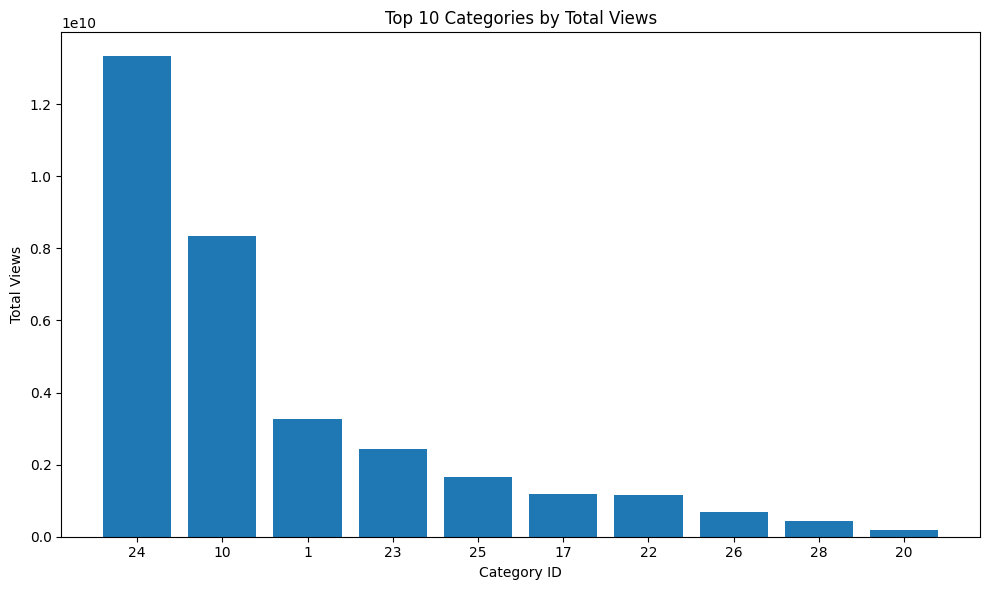

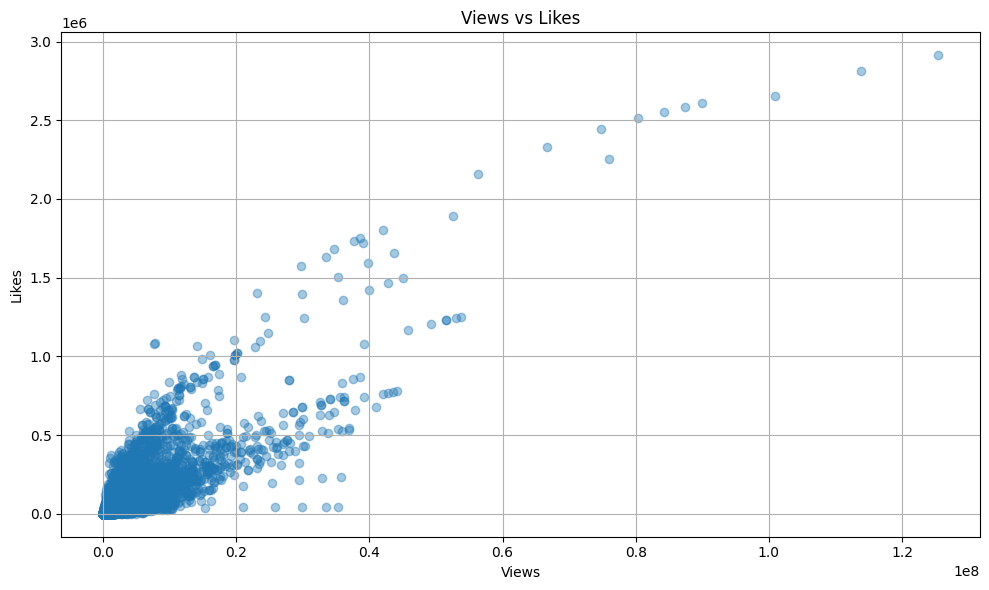

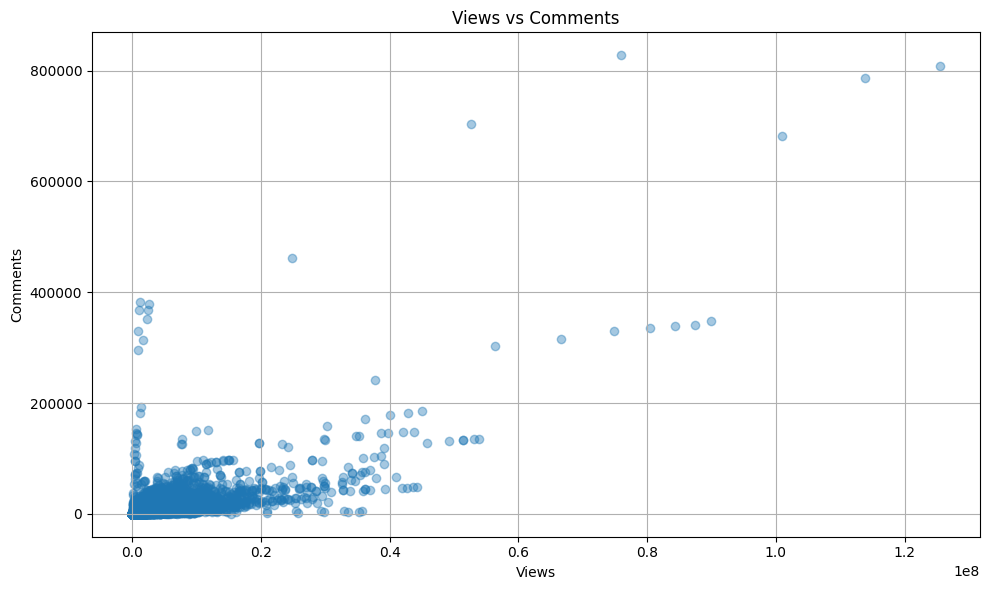

/tmp/ipykernel_15288/60460326.py:200: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128293 (\N{FIRE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


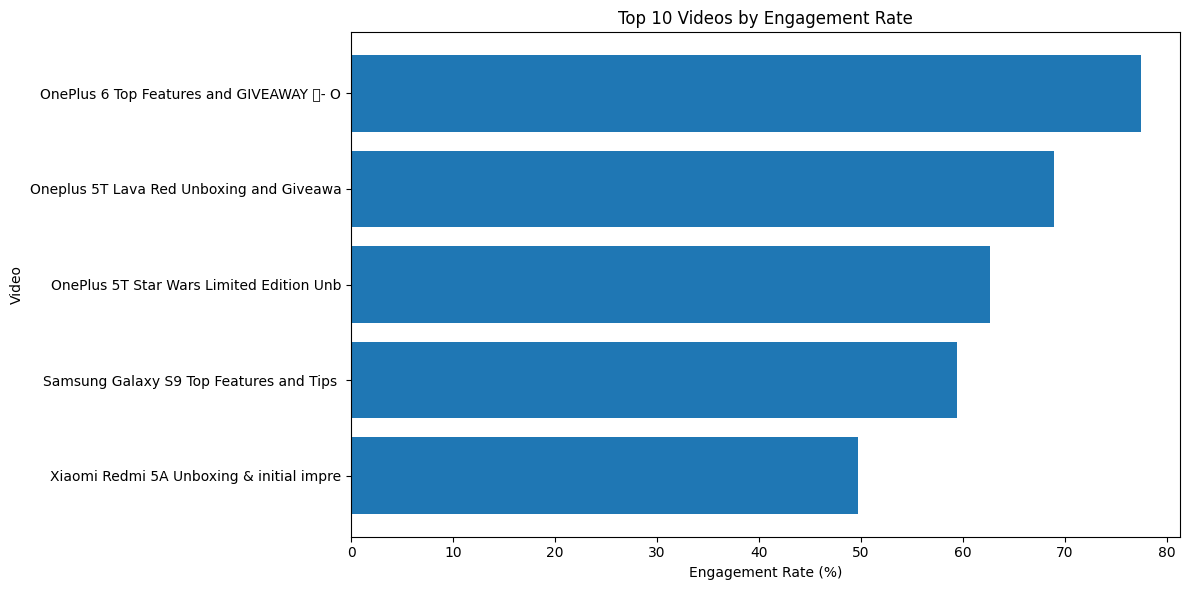

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# ==========================================
# DASHBOARD HEADER
# ==========================================

display(HTML("""
<div style="
    background: #e60000;
    color: white;
    padding: 25px;
    border-radius: 15px;
    text-align: center;
    margin-bottom: 20px;
">
    <h1 style="margin:0;">▶ YouTube Video Statistics Dashboard</h1>
    <p style="font-size:16px;">
        Trending YouTube Videos Analysis using PySpark
    </p>
</div>
"""))


# ==========================================
# KPI CARDS
# ==========================================

display(HTML(f"""
<div style="
display:flex;
gap:15px;
margin-bottom:25px;
">

<div style="
flex:1;
background:#f2f2f2;
padding:20px;
border-radius:12px;
text-align:center;
">
<h3>Total Videos</h3>
<h2>{total_videos:,}</h2>
</div>

<div style="
flex:1;
background:#f2f2f2;
padding:20px;
border-radius:12px;
text-align:center;
">
<h3>Total Views</h3>
<h2>{total_views/1e9:.2f} B</h2>
</div>

<div style="
flex:1;
background:#f2f2f2;
padding:20px;
border-radius:12px;
text-align:center;
">
<h3>Total Likes</h3>
<h2>{total_likes/1e6:.2f} M</h2>
</div>

<div style="
flex:1;
background:#f2f2f2;
padding:20px;
border-radius:12px;
text-align:center;
">
<h3>Total Comments</h3>
<h2>{total_comments/1e6:.2f} M</h2>
</div>

</div>
"""))


# ==========================================
# PREPARE DATA
# ==========================================

channel_dashboard = channel_analysis.limit(10).toPandas()

category_dashboard = category_analysis.limit(10).toPandas()

engagement_dashboard = youtube_df.orderBy(
    col("engagement_rate").desc()
).limit(10).select(
    "title",
    "engagement_rate"
).toPandas()

views_likes_dashboard = youtube_df.select(
    "views",
    "likes"
).toPandas()

views_comments_dashboard = youtube_df.select(
    "views",
    "comment_count"
).toPandas()


# ==========================================
# DASHBOARD GRAPHS
# ==========================================

plt.figure(figsize=(12,6))

plt.bar(
    channel_dashboard["channel_title"],
    channel_dashboard["total_views"]
)

plt.title("Top 10 Channels by Total Views")
plt.xlabel("Channel")
plt.ylabel("Total Views")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


# ==========================================

plt.figure(figsize=(10,6))

plt.bar(
    category_dashboard["category_id"],
    category_dashboard["total_views"]
)

plt.title("Top 10 Categories by Total Views")
plt.xlabel("Category ID")
plt.ylabel("Total Views")

plt.tight_layout()
plt.show()


# ==========================================

plt.figure(figsize=(10,6))

plt.scatter(
    views_likes_dashboard["views"],
    views_likes_dashboard["likes"],
    alpha=0.4
)

plt.title("Views vs Likes")
plt.xlabel("Views")
plt.ylabel("Likes")
plt.grid(True)

plt.tight_layout()
plt.show()


# ==========================================

plt.figure(figsize=(10,6))

plt.scatter(
    views_comments_dashboard["views"],
    views_comments_dashboard["comment_count"],
    alpha=0.4
)

plt.title("Views vs Comments")
plt.xlabel("Views")
plt.ylabel("Comments")
plt.grid(True)

plt.tight_layout()
plt.show()


# ==========================================

plt.figure(figsize=(12,6))

plt.barh(
    engagement_dashboard["title"].str[:40],
    engagement_dashboard["engagement_rate"]
)

plt.title("Top 10 Videos by Engagement Rate")
plt.xlabel("Engagement Rate (%)")
plt.ylabel("Video")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


# ==========================================
# FINAL INSIGHTS
# ==========================================

display(HTML("""
<div style="
background:#f7f7f7;
padding:25px;
border-radius:15px;
margin-top:20px;
">

<h2>📌 Key Findings</h2>

<ul style="font-size:16px; line-height:1.8;">
<li>T-Series generated the highest total views among the analyzed channels.</li>
<li>Category ID 24 recorded the highest total views.</li>
<li>Views and likes show an overall positive relationship.</li>
<li>Views and comments also show an overall positive relationship.</li>
<li>Technology and giveaway videos achieved very high engagement rates.</li>
</ul>

</div>
"""))

In [ ]:
!pip install dash jupyter-dash plotly -q

In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr
import plotly.express as px
from pyspark.sql.functions import col, sum

# =========================================================
# ANALYSIS FUNCTION
# =========================================================

def perform_analysis(analysis_type, top_n):

    top_n = int(top_n)

    # -----------------------------
    # TOP VIEWED VIDEOS
    # -----------------------------
    if analysis_type == "Top Viewed Videos":

        result = (
            youtube_df
            .select(
                "title",
                "channel_title",
                "views",
                "likes",
                "comment_count"
            )
            .orderBy(col("views").desc())
            .limit(top_n)
            .toPandas()
        )

        fig = px.bar(
            result,
            x="views",
            y="title",
            orientation="h",
            title=f"Top {top_n} Most Viewed Videos"
        )

    # -----------------------------
    # TOP LIKED VIDEOS
    # -----------------------------
    elif analysis_type == "Top Liked Videos":

        result = (
            youtube_df
            .select(
                "title",
                "channel_title",
                "views",
                "likes",
                "comment_count"
            )
            .orderBy(col("likes").desc())
            .limit(top_n)
            .toPandas()
        )

        fig = px.bar(
            result,
            x="likes",
            y="title",
            orientation="h",
            title=f"Top {top_n} Most Liked Videos"
        )

    # -----------------------------
    # TOP COMMENTED VIDEOS
    # -----------------------------
    elif analysis_type == "Top Commented Videos":

        result = (
            youtube_df
            .select(
                "title",
                "channel_title",
                "views",
                "likes",
                "comment_count"
            )
            .orderBy(col("comment_count").desc())
            .limit(top_n)
            .toPandas()
        )

        fig = px.bar(
            result,
            x="comment_count",
            y="title",
            orientation="h",
            title=f"Top {top_n} Most Commented Videos"
        )

    # -----------------------------
    # TOP CHANNELS
    # -----------------------------
    elif analysis_type == "Top Channels":

        result = (
            youtube_df
            .groupBy("channel_title")
            .agg(
                sum("views").alias("total_views"),
                sum("likes").alias("total_likes"),
                sum("comment_count").alias("total_comments")
            )
            .orderBy(col("total_views").desc())
            .limit(top_n)
            .toPandas()
        )

        fig = px.bar(
            result,
            x="total_views",
            y="channel_title",
            orientation="h",
            title=f"Top {top_n} Channels by Total Views"
        )

    # -----------------------------
    # CATEGORY ANALYSIS
    # -----------------------------
    elif analysis_type == "Category Analysis":

        result = (
            youtube_df
            .groupBy("category_id")
            .agg(
                sum("views").alias("total_views"),
                sum("likes").alias("total_likes"),
                sum("comment_count").alias("total_comments")
            )
            .orderBy(col("total_views").desc())
            .limit(top_n)
            .toPandas()
        )

        fig = px.bar(
            result,
            x="category_id",
            y="total_views",
            title=f"Top {top_n} Categories by Views"
        )

    # -----------------------------
    # ENGAGEMENT ANALYSIS
    # -----------------------------
    elif analysis_type == "Engagement Analysis":

        result = (
            youtube_df
            .select(
                "title",
                "channel_title",
                "views",
                "likes",
                "comment_count",
                "engagement_rate"
            )
            .orderBy(col("engagement_rate").desc())
            .limit(top_n)
            .toPandas()
        )

        fig = px.bar(
            result,
            x="engagement_rate",
            y="title",
            orientation="h",
            title=f"Top {top_n} Videos by Engagement Rate"
        )

    # -----------------------------
    # VIEWS VS LIKES
    # -----------------------------
    elif analysis_type == "Views vs Likes":

        result = (
            youtube_df
            .select(
                "title",
                "views",
                "likes"
            )
            .sample(False, 0.10, seed=42)
            .limit(5000)
            .toPandas()
        )

        fig = px.scatter(
            result,
            x="views",
            y="likes",
            hover_name="title",
            title="Views vs Likes"
        )

    # -----------------------------
    # VIEWS VS COMMENTS
    # -----------------------------
    elif analysis_type == "Views vs Comments":

        result = (
            youtube_df
            .select(
                "title",
                "views",
                "comment_count"
            )
            .sample(False, 0.10, seed=42)
            .limit(5000)
            .toPandas()
        )

        fig = px.scatter(
            result,
            x="views",
            y="comment_count",
            hover_name="title",
            title="Views vs Comments"
        )

    # -----------------------------
    # GRAPH DESIGN
    # -----------------------------

    fig.update_layout(
        template="plotly_dark",
        height=500,
        margin=dict(l=20, r=20, t=60, b=20)
    )

    return result, fig


# =========================================================
# GRADIO UI
# =========================================================

with gr.Blocks(
    theme=gr.themes.Soft(),
    title="YouTube Big Data Analytics"
) as demo:

    gr.Markdown(
        """
        # 📊 YouTube Video Statistics Analytics
        ### Big Data Analytics using PySpark

        Select the analysis you want to perform.
        """
    )

    with gr.Row():

        analysis_dropdown = gr.Dropdown(
            choices=[
                "Top Viewed Videos",
                "Top Liked Videos",
                "Top Commented Videos",
                "Top Channels",
                "Category Analysis",
                "Engagement Analysis",
                "Views vs Likes",
                "Views vs Comments"
            ],
            value="Top Viewed Videos",
            label="🔍 Select Analysis"
        )

        top_n = gr.Dropdown(
            choices=[5, 10, 15, 20],
            value=10,
            label="Number of Results"
        )

        analyze_btn = gr.Button(
            "🚀 Analyze",
            variant="primary"
        )

    gr.Markdown("---")

    result_table = gr.Dataframe(
        label="📋 Analysis Results",
        interactive=False
    )

    result_graph = gr.Plot(
        label="📈 Visualization"
    )

    analyze_btn.click(
        fn=perform_analysis,
        inputs=[analysis_dropdown, top_n],
        outputs=[result_table, result_graph]
    )


# =========================================================
# LAUNCH
# =========================================================

demo.launch(
    share=True,
    debug=False
)

/tmp/ipykernel_15288/1575184038.py:240: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c43cbfcfb0e9ce9b3d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import gradio as gr

# =========================================================
# YOUTUBE-THEMED GRADIO INTERFACE
# Requires your existing perform_analysis() function
# =========================================================

youtube_theme = gr.themes.Base(
    primary_hue=gr.themes.colors.red,
    secondary_hue=gr.themes.colors.neutral,
    neutral_hue=gr.themes.colors.zinc
)

custom_css = """
body {
    background-color: #0F0F0F !important;
}

.gradio-container {
    max-width: 1250px !important;
    margin: auto !important;
    background-color: #0F0F0F !important;
    color: #FFFFFF !important;
}

/* Header */
#youtube-header {
    background: linear-gradient(135deg, #181818, #252525);
    border: 1px solid #383838;
    border-radius: 16px;
    padding: 25px;
    margin-bottom: 18px;
}

#youtube-logo {
    color: #FF0000;
    font-size: 30px;
    font-weight: 800;
}

#youtube-title {
    color: #FFFFFF;
    font-size: 27px;
    font-weight: 700;
    margin-top: 8px;
}

#youtube-subtitle {
    color: #AAAAAA;
    font-size: 15px;
    margin-top: 8px;
}

/* Analyze button */
#analyze-button {
    background: #FF0000 !important;
    color: #FFFFFF !important;
    border: none !important;
    border-radius: 10px !important;
    font-weight: bold !important;
    min-height: 45px;
}

#analyze-button:hover {
    background: #CC0000 !important;
}

/* Results panels */
.panel {
    border: 1px solid #383838 !important;
    border-radius: 12px !important;
}

/* Section headings */
.section-title {
    color: #FFFFFF;
    font-size: 20px;
    font-weight: 700;
    margin: 18px 0 12px 0;
}

/* Footer */
#youtube-footer {
    color: #AAAAAA;
    text-align: center;
    padding: 20px;
    font-size: 13px;
}
"""

with gr.Blocks(
    theme=youtube_theme,
    css=custom_css,
    title="YouTube Video Statistics Analytics"
) as demo:

    # ---------------- HEADER ----------------
    gr.HTML("""
    <div id="youtube-header">
        <div id="youtube-logo">▶ YouTube Analytics</div>
        <div id="youtube-title">Video Statistics Dashboard</div>
        <div id="youtube-subtitle">
            Big Data Analytics using Apache Spark (PySpark)
        </div>
        <p style="color:#FFFFFF; margin-top:15px;">
            Explore video popularity, channel performance,
            category trends and audience engagement.
        </p>
    </div>
    """)

    # ---------------- INPUT CONTROLS ----------------
    gr.Markdown("## Select Your Analysis")

    with gr.Row():

        analysis_dropdown = gr.Dropdown(
            choices=[
                "Top Viewed Videos",
                "Top Liked Videos",
                "Top Commented Videos",
                "Top Channels",
                "Category Analysis",
                "Engagement Analysis",
                "Views vs Likes",
                "Views vs Comments"
            ],
            value="Top Viewed Videos",
            label="🔍 Select Analysis",
            scale=3
        )

        top_n = gr.Dropdown(
            choices=[5, 10, 15, 20],
            value=10,
            label="Number of Results",
            scale=1
        )

    analyze_btn = gr.Button(
        "▶  Analyze Data",
        variant="primary",
        elem_id="analyze-button"
    )

    gr.Markdown("---")

    # ---------------- OUTPUTS ----------------
    gr.HTML('<div class="section-title">📊 Analysis Results</div>')

    with gr.Column(elem_classes=["panel"]):

        result_table = gr.Dataframe(
            label="Results Table",
            interactive=False,
            wrap=True
        )

        result_graph = gr.Plot(
            label="Data Visualization"
        )

    # ---------------- BUTTON ACTION ----------------
    analyze_btn.click(
        fn=perform_analysis,
        inputs=[
            analysis_dropdown,
            top_n
        ],
        outputs=[
            result_table,
            result_graph
        ]
    )

    # ---------------- FOOTER ----------------
    gr.HTML("""
    <div id="youtube-footer">
        YouTube Video Statistics Analysis<br>
        Powered by PySpark • Plotly • Gradio
    </div>
    """)

# =========================================================
# LAUNCH INTERFACE
# =========================================================

demo.launch(
    share=True,
    debug=False
)

/tmp/ipykernel_15288/2330232155.py:91: UserWarning:

The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.



Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://92e837fc4d956df921.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
